## Step 6 & 7 - Optuna tuning of the 3 models + MLflow tracking

In [1]:
import os
import json
import time
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna
import mlflow
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier

In [2]:
from features import build_full_pipeline, load_data

warnings.filterwarnings("ignore")
os.makedirs("plots", exist_ok=True)
os.makedirs("results", exist_ok=True)
os.makedirs("models", exist_ok=True)

In [3]:
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("bank_marketing_tuning")

X_dev, y_dev, X_test, y_test = load_data()
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

2026/10/15 15:54:21 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/10/15 15:54:21 INFO mlflow.store.db.utils: Updating database tables


2026/10/15 15:54:21 INFO mlflow.tracking.fluent: Experiment with name 'bank_marketing_tuning' does not exist. Creating a new experiment.


In [4]:
# number of Optuna trials for each model
n_trials = {"logistic_regression": 20, "random_forest": 25, "lightgbm": 30}


def suggest_params(model_name, trial):
    # search space of each model
    if model_name == "logistic_regression":
        params = {
            "C": trial.suggest_float("C", 0.001, 10, log=True),
            # l1_ratio: 0 = Ridge (L2), 1 = Lasso (L1), in between = Elastic Net (session 2)
            "l1_ratio": trial.suggest_float("l1_ratio", 0.0, 1.0),
            "class_weight": trial.suggest_categorical("class_weight", [None, "balanced"]),
        }
    elif model_name == "random_forest":
        params = {
            "n_estimators": trial.suggest_int("n_estimators", 100, 400),
            "max_depth": trial.suggest_int("max_depth", 4, 20),
            "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 50),
            "max_features": trial.suggest_float("max_features", 0.1, 0.7),
            "class_weight": trial.suggest_categorical("class_weight", [None, "balanced"]),
        }
    else:
        params = {
            "n_estimators": trial.suggest_int("n_estimators", 50, 500),
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
            "num_leaves": trial.suggest_int("num_leaves", 8, 100),
            "max_depth": trial.suggest_int("max_depth", 3, 12),
            "min_child_samples": trial.suggest_int("min_child_samples", 10, 200),
            "subsample": trial.suggest_float("subsample", 0.6, 1.0),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.4, 1.0),
            "reg_lambda": trial.suggest_float("reg_lambda", 0.001, 10, log=True),
            # weight of the positive class (session 6: N_neg / N_pos = 7.5 is only a starting point)
            "scale_pos_weight": trial.suggest_float("scale_pos_weight", 1.0, 8.0),
        }
    return params

In [5]:
def make_model(model_name, params):
    if model_name == "logistic_regression":
        model = LogisticRegression(**params, solver="saga", max_iter=2000, random_state=42)
    elif model_name == "random_forest":
        model = RandomForestClassifier(**params, random_state=42, n_jobs=-1)
    else:
        # subsample only works in LightGBM if subsample_freq > 0 (it was missing in 04_hyperparameter_tuning.py)
        model = LGBMClassifier(**params, subsample_freq=1, random_state=42, n_jobs=-1, verbose=-1)
    return model

In [6]:
def objective(trial, model_name):
    params = suggest_params(model_name, trial)
    pipeline = build_full_pipeline(make_model(model_name, params))

    start = time.time()
    scores = cross_validate(pipeline, X_dev, y_dev, cv=cv,
                            scoring=["average_precision", "roc_auc"], n_jobs=-1)
    duration = time.time() - start

    pr_auc = scores["test_average_precision"].mean()

    # one MLflow run for each trial (inside the run of the model)
    with mlflow.start_run(run_name=model_name + "_trial_" + str(trial.number), nested=True):
        mlflow.log_param("model", model_name)
        mlflow.log_param("trial_number", trial.number)
        mlflow.log_params(params)
        mlflow.log_metric("cv_pr_auc", pr_auc)
        mlflow.log_metric("cv_pr_auc_std", scores["test_average_precision"].std())
        mlflow.log_metric("cv_roc_auc", scores["test_roc_auc"].mean())
        mlflow.log_metric("cv_time_seconds", duration)

    return pr_auc


========== TUNING logistic_regression ==========


[I 2026-10-15 15:54:22,081] A new study created in memory with name: no-name-7de88043-bb1e-42f5-bc61-b1dcb97d2107


[I 2026-10-15 15:54:35,547] Trial 0 finished with value: 0.4017371722131758 and parameters: {'C': 0.03148911647956861, 'l1_ratio': 0.9507143064099162, 'class_weight': None}. Best is trial 0 with value: 0.4017371722131758.


[I 2026-10-15 15:54:41,484] Trial 1 finished with value: 0.3893496685349471 and parameters: {'C': 0.004207988669606638, 'l1_ratio': 0.15599452033620265, 'class_weight': 'balanced'}. Best is trial 0 with value: 0.4017371722131758.


[I 2026-10-15 15:54:58,219] Trial 2 finished with value: 0.39910725231654476 and parameters: {'C': 0.25378155082656645, 'l1_ratio': 0.7080725777960455, 'class_weight': 'balanced'}. Best is trial 0 with value: 0.4017371722131758.


...

[I 2026-10-15 15:58:47,190] Trial 16 finished with value: 0.403100265716026 and parameters: {'C': 0.15540296647821722, 'l1_ratio': 0.2180084121200408, 'class_weight': None}. Best is trial 16 with value: 0.403100265716026.


[I 2026-10-15 15:59:15,151] Trial 17 finished with value: 0.40304230796802976 and parameters: {'C': 0.16597198071372302, 'l1_ratio': 0.29594155833675895, 'class_weight': None}. Best is trial 16 with value: 0.403100265716026.


[I 2026-10-15 15:59:27,018] Trial 18 finished with value: 0.3991195315892894 and parameters: {'C': 0.15333730577234117, 'l1_ratio': 0.3689879327985793, 'class_weight': 'balanced'}. Best is trial 16 with value: 0.403100265716026.


[I 2026-10-15 15:59:54,613] Trial 19 finished with value: 0.40350044852242134 and parameters: {'C': 0.037793848644199775, 'l1_ratio': 0.3325108768864191, 'class_weight': None}. Best is trial 19 with value: 0.40350044852242134.


Best CV PR-AUC: 0.4035
Best params: {'C': 0.037793848644199775, 'l1_ratio': 0.3325108768864191, 'class_weight': None}


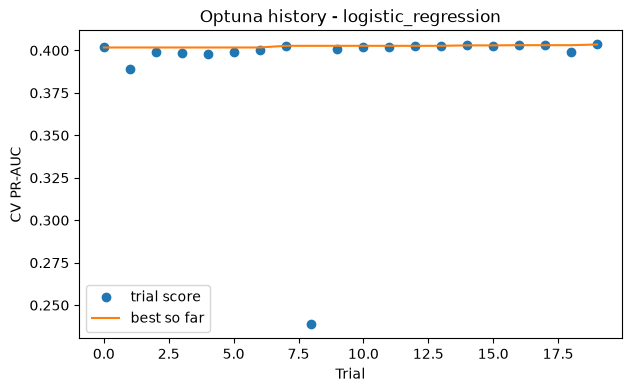

[I 2026-10-15 16:00:17,085] A new study created in memory with name: no-name-976d989f-1f66-4a4d-9d24-6e6b6c031a92



========== TUNING random_forest ==========


[I 2026-10-15 16:00:24,281] Trial 0 finished with value: 0.43932884925088017 and parameters: {'n_estimators': 212, 'max_depth': 20, 'min_samples_leaf': 37, 'max_features': 0.45919509051822194, 'class_weight': None}. Best is trial 0 with value: 0.43932884925088017.


[I 2026-10-15 16:00:27,723] Trial 1 finished with value: 0.43720133333249916 and parameters: {'n_estimators': 117, 'max_depth': 18, 'min_samples_leaf': 31, 'max_features': 0.5248435466776273, 'class_weight': 'balanced'}. Best is trial 0 with value: 0.43932884925088017.


[I 2026-10-15 16:00:31,545] Trial 2 finished with value: 0.4234730165706576 and parameters: {'n_estimators': 350, 'max_depth': 7, 'min_samples_leaf': 10, 'max_features': 0.21004270591206028, 'class_weight': 'balanced'}. Best is trial 0 with value: 0.43932884925088017.


...

[I 2026-10-15 16:02:34,259] Trial 21 finished with value: 0.4467414429042299 and parameters: {'n_estimators': 180, 'max_depth': 18, 'min_samples_leaf': 4, 'max_features': 0.4106925650497688, 'class_weight': None}. Best is trial 4 with value: 0.4470127714324123.


[I 2026-10-15 16:02:51,376] Trial 22 finished with value: 0.4451951931220474 and parameters: {'n_estimators': 332, 'max_depth': 20, 'min_samples_leaf': 7, 'max_features': 0.6219469041822361, 'class_weight': None}. Best is trial 4 with value: 0.4470127714324123.


[I 2026-10-15 16:02:59,136] Trial 23 finished with value: 0.4478641299146619 and parameters: {'n_estimators': 246, 'max_depth': 17, 'min_samples_leaf': 5, 'max_features': 0.34804845981562765, 'class_weight': None}. Best is trial 23 with value: 0.4478641299146619.


[I 2026-10-15 16:03:06,094] Trial 24 finished with value: 0.4459710781699588 and parameters: {'n_estimators': 252, 'max_depth': 15, 'min_samples_leaf': 11, 'max_features': 0.35758803952516915, 'class_weight': None}. Best is trial 23 with value: 0.4478641299146619.


Best CV PR-AUC: 0.4479
Best params: {'n_estimators': 246, 'max_depth': 17, 'min_samples_leaf': 5, 'max_features': 0.34804845981562765, 'class_weight': None}


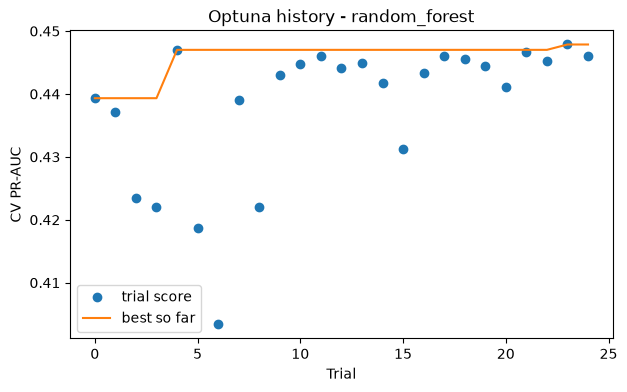

[I 2026-10-15 16:03:08,166] A new study created in memory with name: no-name-caf828db-b415-4402-9dd8-56d00c7bcf4b



========== TUNING lightgbm ==========


[I 2026-10-15 16:03:23,140] Trial 0 finished with value: 0.41665561939378043 and parameters: {'n_estimators': 218, 'learning_rate': 0.17254716573280354, 'num_leaves': 76, 'max_depth': 8, 'min_child_samples': 39, 'subsample': 0.662397808134481, 'colsample_bytree': 0.4348501673009197, 'reg_lambda': 2.915443189153755, 'scale_pos_weight': 5.207805082202461}. Best is trial 0 with value: 0.41665561939378043.


[I 2026-10-15 16:04:13,063] Trial 1 finished with value: 0.4534067733624204 and parameters: {'n_estimators': 369, 'learning_rate': 0.010636066512540286, 'num_leaves': 98, 'max_depth': 11, 'min_child_samples': 50, 'subsample': 0.6727299868828402, 'colsample_bytree': 0.5100427059120604, 'reg_lambda': 0.016480446427978974, 'scale_pos_weight': 4.673295021425665}. Best is trial 1 with value: 0.4534067733624204.


[I 2026-10-15 16:04:16,048] Trial 2 finished with value: 0.44106349571078346 and parameters: {'n_estimators': 244, 'learning_rate': 0.023927528765580634, 'num_leaves': 64, 'max_depth': 4, 'min_child_samples': 65, 'subsample': 0.7465447373174766, 'colsample_bytree': 0.6736419905302216, 'reg_lambda': 1.3826232179369866, 'scale_pos_weight': 2.3977164751085183}. Best is trial 1 with value: 0.4534067733624204.


...

[I 2026-10-15 16:11:14,345] Trial 26 finished with value: 0.454087064049865 and parameters: {'n_estimators': 286, 'learning_rate': 0.017023844489006592, 'num_leaves': 45, 'max_depth': 12, 'min_child_samples': 20, 'subsample': 0.7408921843125745, 'colsample_bytree': 0.4625137813974732, 'reg_lambda': 0.009105124424337177, 'scale_pos_weight': 2.5475379310966355}. Best is trial 12 with value: 0.45595445606319257.


[I 2026-10-15 16:11:41,845] Trial 27 finished with value: 0.4548618317810365 and parameters: {'n_estimators': 424, 'learning_rate': 0.014559203535360788, 'num_leaves': 62, 'max_depth': 12, 'min_child_samples': 47, 'subsample': 0.6401938987333583, 'colsample_bytree': 0.5015316335861615, 'reg_lambda': 0.018870055285033008, 'scale_pos_weight': 1.6927257192689988}. Best is trial 12 with value: 0.45595445606319257.


[I 2026-10-15 16:12:15,143] Trial 28 finished with value: 0.45581114720289273 and parameters: {'n_estimators': 375, 'learning_rate': 0.010570440335792079, 'num_leaves': 79, 'max_depth': 12, 'min_child_samples': 20, 'subsample': 0.7475174377845564, 'colsample_bytree': 0.5704302888645865, 'reg_lambda': 0.010517163154906028, 'scale_pos_weight': 3.3641240611677077}. Best is trial 12 with value: 0.45595445606319257.


[I 2026-10-15 16:12:31,694] Trial 29 finished with value: 0.4530955026016244 and parameters: {'n_estimators': 243, 'learning_rate': 0.013780122461019893, 'num_leaves': 52, 'max_depth': 12, 'min_child_samples': 38, 'subsample': 0.7179457166726865, 'colsample_bytree': 0.5713217635760073, 'reg_lambda': 0.009862092715174528, 'scale_pos_weight': 2.6994067831568835}. Best is trial 12 with value: 0.45595445606319257.


Best CV PR-AUC: 0.456
Best params: {'n_estimators': 318, 'learning_rate': 0.017393186289334832, 'num_leaves': 87, 'max_depth': 12, 'min_child_samples': 32, 'subsample': 0.6442112253464464, 'colsample_bytree': 0.5289358611864258, 'reg_lambda': 0.004276540348091623, 'scale_pos_weight': 2.680428972413698}


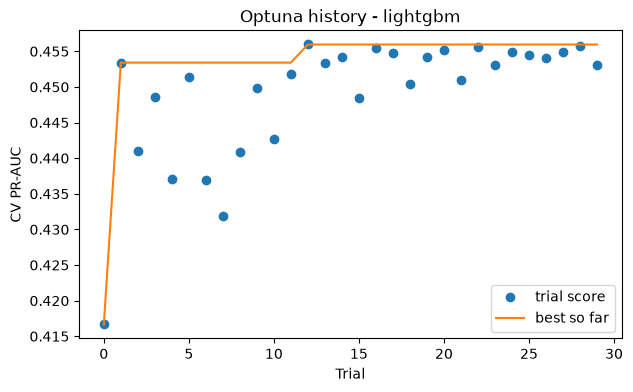

In [7]:
best_params = {}
summary = []

for model_name in n_trials:
    print("\n========== TUNING", model_name, "==========")

    with mlflow.start_run(run_name=model_name + "_optuna_study"):
        mlflow.log_param("model", model_name)
        mlflow.log_param("n_trials", n_trials[model_name])
        mlflow.log_param("cv", "5-fold stratified")
        mlflow.log_param("metric", "PR-AUC (average precision)")

        study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
        study.optimize(lambda trial: objective(trial, model_name), n_trials=n_trials[model_name])

        print("Best CV PR-AUC:", round(study.best_value, 4))
        print("Best params:", study.best_params)

        for key in study.best_params:
            mlflow.log_param("best_" + key, study.best_params[key])
        mlflow.log_metric("best_cv_pr_auc", study.best_value)

        # all the trials in a csv
        trials_df = study.trials_dataframe()
        trials_df.to_csv("results/optuna_trials_" + model_name + ".csv", index=False)
        mlflow.log_artifact("results/optuna_trials_" + model_name + ".csv")

        # plot: score of each trial + best score so far
        values = trials_df["value"].values
        plt.figure(figsize=(7, 4))
        plt.plot(values, "o", label="trial score")
        plt.plot(np.maximum.accumulate(values), "-", label="best so far")
        plt.xlabel("Trial")
        plt.ylabel("CV PR-AUC")
        plt.title("Optuna history - " + model_name)
        plt.legend()
        plt.savefig("plots/optuna_history_" + model_name + ".png", dpi=150, bbox_inches="tight")
        plt.show()
        mlflow.log_artifact("plots/optuna_history_" + model_name + ".png")

        # refit the best pipeline on the whole dev set and save it
        best_pipeline = build_full_pipeline(make_model(model_name, study.best_params))
        best_pipeline.fit(X_dev, y_dev)
        joblib.dump(best_pipeline, "models/best_" + model_name + ".pkl")
        mlflow.log_artifact("models/best_" + model_name + ".pkl")

        best_params[model_name] = study.best_params
        summary.append({"model": model_name, "n_trials": n_trials[model_name],
                        "best_cv_pr_auc": study.best_value})

In [8]:
# save the best params for the next scripts
with open("models/best_params.json", "w") as f:
    json.dump(best_params, f, indent=4)

summary_df = pd.DataFrame(summary)
print("\n--- SUMMARY OF THE TUNING ---")
print(summary_df.round(4).to_string(index=False))
summary_df.to_csv("results/tuning_summary.csv", index=False)


--- SUMMARY OF THE TUNING ---
              model  n_trials  best_cv_pr_auc
logistic_regression        20          0.4035
      random_forest        25          0.4479
           lightgbm        30          0.4560


In [9]:
# export of all the MLflow runs (so we have them in the repo / report)
runs = mlflow.search_runs(experiment_names=["bank_marketing_tuning"])
runs.to_csv("results/mlflow_runs.csv", index=False)
print("Number of MLflow runs logged:", len(runs))

Number of MLflow runs logged: 78
